# Eksploracyjna Analiza Danych

Praca ma na celu zbadanie atrakcyjności turystycznej bałkańskich regionów NUTS2. Pod uwagę zostaną wzięte zmienne:
- Liczba zarezerwowanych noclegów ogółem
- Ilość noclegów zarezerwowanych przez osoby zza granicy (do późniejszego wyliczenia stosunku ich do ogółu)
- Liczba obiektów
- Ruch lotniczy (dla regionów posiadających lotniska)
- Poziom cen dla sektoru turystycznego (raportowany na poziomie NUTS0)
- Jakość wód kąpielowych (NUTS0)


# Wczytanie potrzebnych bibliotek

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn as sk
import numpy as np

# Wczytanie danych

In [2]:
df = pd.read_excel('baza_balkany.xlsx')

pd.set_option('display.float_format', lambda x: '%.2f' % x)


Przyjrzyjmy się jakie dokładnie mamy dane w zbiorze, oraz zbadajmy ich podstawową charakterystykę

In [3]:
df.head()

,geo,Year,Noclegi_Ogolem,Noclegi_Zagraniczne,Liczba_Obiektow,Ruch_Lotniczy,NUTS0,Poziom_Cen_NUTS0,Wody_Doskonała_Jakość_NUTS0,Robbery
0,AL01,2020,379698,230943,398,1300.00,AL,52.50,113,253
1,AL02,2020,473246,308692,467,5.00,AL,52.50,113,524
2,AL03,2020,625078,208728,592,2.00,AL,52.50,113,456
3,BG31,2020,456173,151260,177,0.00,BG,51.30,92,286
4,BG32,2020,419053,84202,286,0.00,BG,51.30,92,292


Jak widać dysponujemy różnymi cechami danych dal poszczególnych regionach w cztertech różnych okresach czasu. Teraz spójrzmy na typ danych

In [4]:
df.dtypes

geo                             object
Year                             int64
Noclegi_Ogolem                   int64
Noclegi_Zagraniczne              int64
Liczba_Obiektow                  int64
Ruch_Lotniczy                  float64
NUTS0                           object
Poziom_Cen_NUTS0               float64
Wody_Doskonała_Jakość_NUTS0      int64
Robbery                          int64
dtype: object

Ponieważ typ Geo bezpośrednio nie niesie nam żadnej informacji a jedynie pozwala rozróżnić obiekty od siebie, zamienimy go na zmienną faktorową. 
Zmienną rok również przekonwertujemy na faktor. Po tej zmianie sprawdzimy podstawowe statystyki dla zmiennych.

In [5]:
df['geo'] = df['geo'].astype('category')
df['Year'] = df['Year'].astype('category')
print(df['Year'].unique())

[2020, 2021, 2022, 2023, 2024]
Categories (5, int64): [2020, 2021, 2022, 2023, 2024]


In [6]:
lata_kategorie = [2020, 2021, 2022, 2023, 2024]

df['Year'] = df['Year'].cat.set_categories(lata_kategorie, ordered=True)

In [7]:
df.describe()


,Noclegi_Ogolem,Noclegi_Zagraniczne,Liczba_Obiektow,Ruch_Lotniczy,Poziom_Cen_NUTS0,Wody_Doskonała_Jakość_NUTS0,Robbery
count,175.00,175.00,175.00,175.00,175.00,175.00,175.00
mean,4304092.78,2967430.86,4915.05,2706.27,66.14,633.94,2789.35
std,6199246.66,5937668.93,17398.40,4958.20,14.15,738.10,4103.89
min,167669.00,22027.00,112.00,0.00,49.40,21.00,95.00
25%,1131622.50,224601.00,695.00,5.13,54.20,49.00,354.00
50%,2069414.00,714878.00,1187.00,582.06,59.30,92.00,667.00
75%,4257218.00,1989722.00,2707.50,3265.29,83.00,1679.00,2853.50
max,32447938.00,30600629.00,115285.00,31599.50,91.00,1728.00,16731.00


Sprawdźmy czy pojawiają się braki danych

In [8]:
df.isnull().sum()

geo                            0
Year                           0
Noclegi_Ogolem                 0
Noclegi_Zagraniczne            0
Liczba_Obiektow                0
Ruch_Lotniczy                  0
NUTS0                          0
Poziom_Cen_NUTS0               0
Wody_Doskonała_Jakość_NUTS0    0
Robbery                        0
dtype: int64



Zbadajmy teraz unikalność danych. W tym celu posłużymy sie wskaźnikiem który pokaże jaki procent z całego zbioru danych w wierszu stanowią wartości unikalne

In [9]:
df.nunique() / len(df) * 100

geo                            22.86
Year                            2.86
Noclegi_Ogolem                100.00
Noclegi_Zagraniczne           100.00
Liczba_Obiektow                96.00
Ruch_Lotniczy                  76.00
NUTS0                           4.00
Poziom_Cen_NUTS0               18.29
Wody_Doskonała_Jakość_NUTS0     6.86
Robbery                        97.71
dtype: float64

W celu unikniecia powielania informacji przyjrzyjmy się wzajemnej korelacji pomiedzy zmiennymi

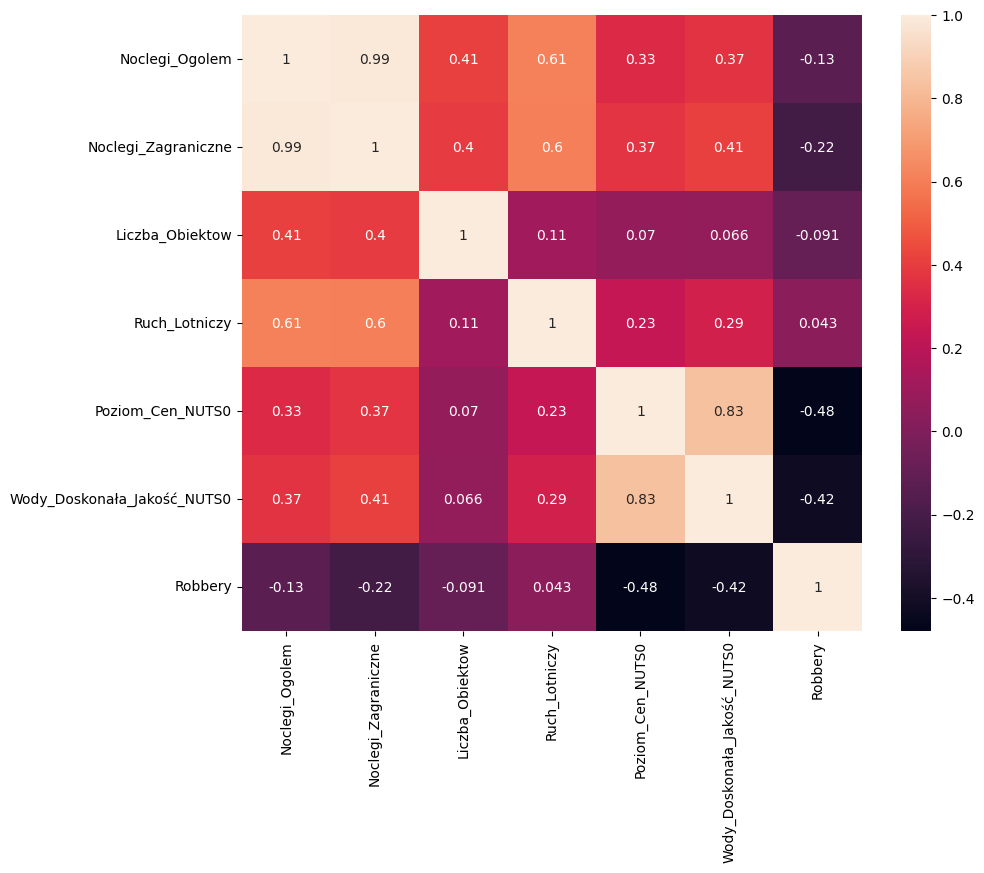

In [10]:
plt.rcParams['figure.figsize'] = (10, 8)
sns.heatmap(df.corr(numeric_only=True), annot=True)    
plt.show()

Co oczywiste zmienna noclegi zagraniczne ma korelację bliską 1 z noclegami ogółem. Jest ona jednak tylko zmienną pomocniczą, którą wykorzystamy do wyliczenia stosunku. Pozostałe zmienne nie są silnie skorelowane. Przyjrzyjmy się zatem temu wskaźnikowi.

In [11]:
df['Udział_Zagranicznych'] = df['Noclegi_Zagraniczne'] / df['Noclegi_Ogolem'] * 100
korelacja = df['Udział_Zagranicznych'].corr(df['Noclegi_Ogolem'])

print(f"Korelacja między udziałem zagranicznym a liczbą turystów ogółem: {korelacja:.4f}")

df = df.drop(columns=['Noclegi_Zagraniczne'])


Korelacja między udziałem zagranicznym a liczbą turystów ogółem: 0.5421


Zobaczmy jaki obszar był ogółem najpopularniejszy

In [12]:
grouped_df = df.groupby('geo')['Noclegi_Ogolem'].sum()
grouped_df.sort_values(ascending=False).head(n=10)


C:\Users\Jan\AppData\Local\Temp\ipykernel_27032\2595806469.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_df = df.groupby('geo')['Noclegi_Ogolem'].sum()


geo
EL42    107403628
EL43    100244819
HR03     85857544
EL62     46964511
EL52     38334622
BG34     37649067
EL30     37508287
RO22     26241097
BG33     24244043
RO12     18987021
Name: Noclegi_Ogolem, dtype: int64

Oraz przyjrzymy sie panujacym trendom 

C:\Users\Jan\AppData\Local\Temp\ipykernel_27032\3382605313.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('Year')['Noclegi_Ogolem'].mean().plot(kind='bar', figsize=(12, 8))


<Axes: xlabel='Year'>

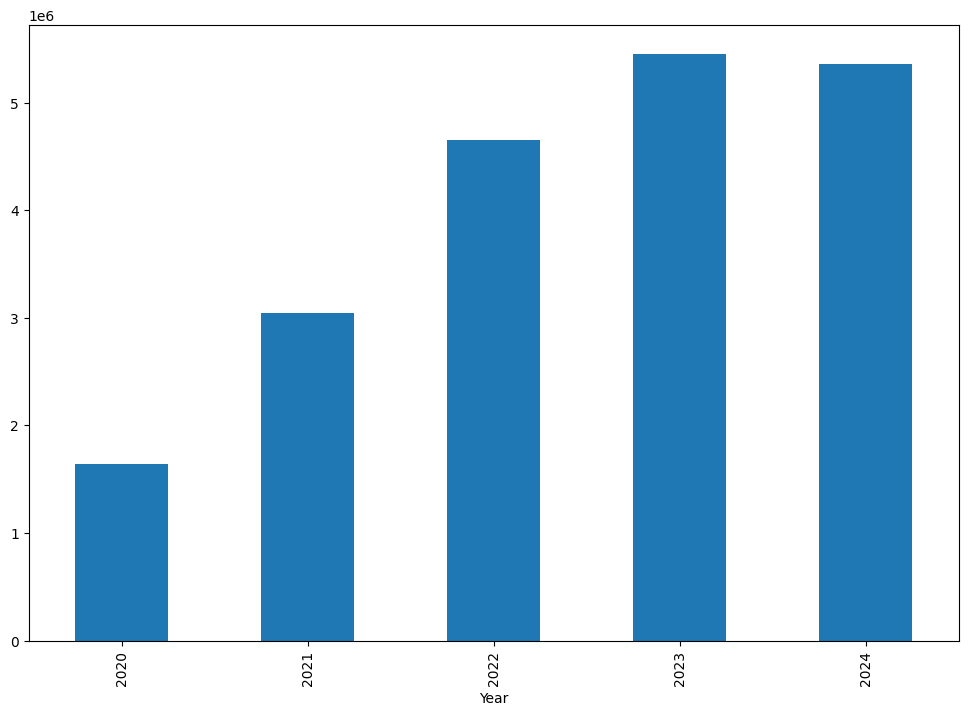

In [13]:
df.groupby('Year')['Noclegi_Ogolem'].mean().plot(kind='bar', figsize=(12, 8))

Jak widać dostajemy dość silny trend wzrostowy który najpewniej jest spowodowany ograniczeniami towarzyszącymi pandemi, w naszej pracy w celu zapewnienia porównywalności zastosujemy standaryzacje.

Najpopularniejszy region to Południowe Wyspy Egejskie

Przyjrzyjmy się teraz zmniennym z osobna. Zacznijmy od przyjrzenia sie temu jak rozkładają sie nasze dane.

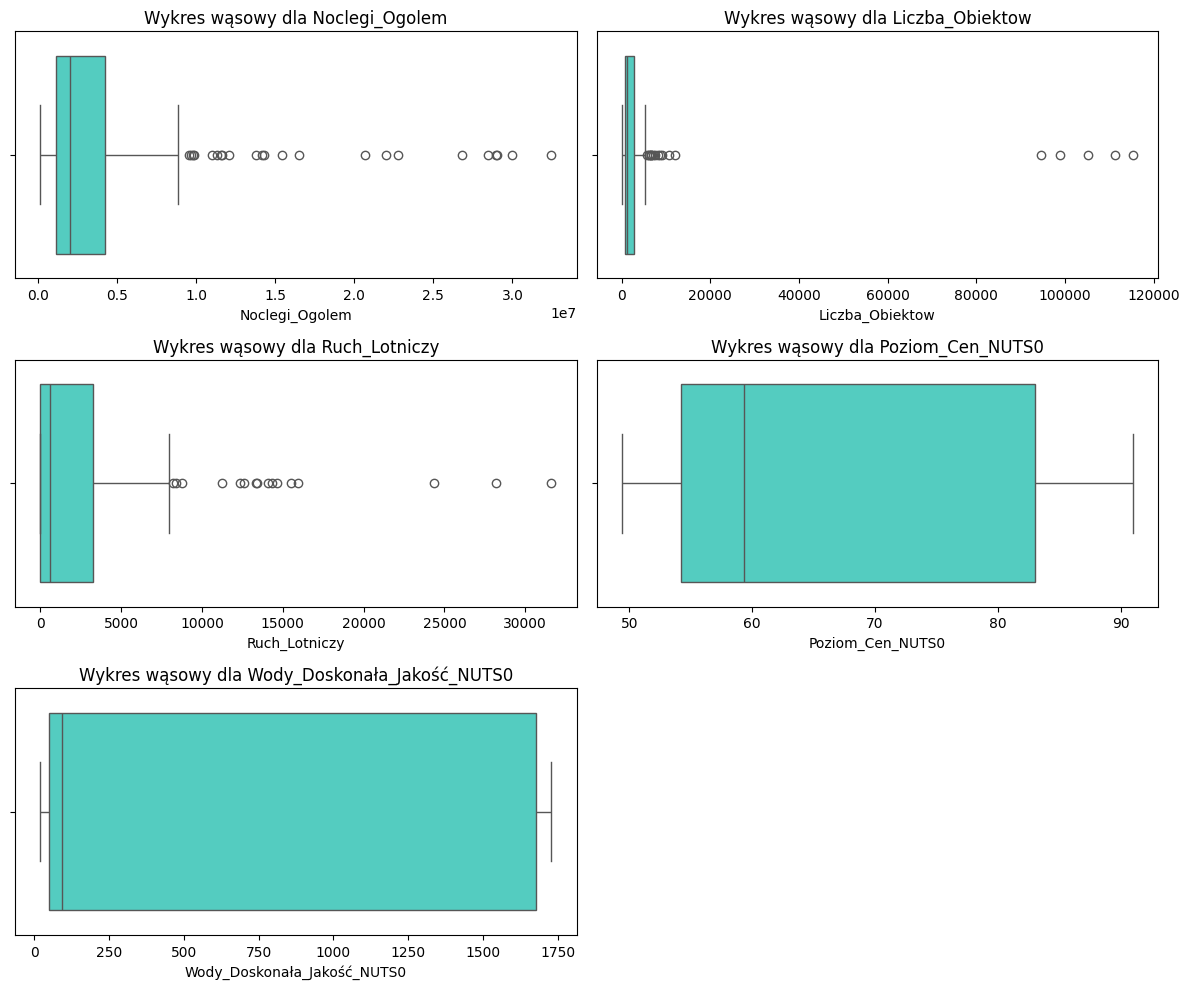

In [14]:
numeric_cols = [
    'Noclegi_Ogolem', 
    'Liczba_Obiektow', 
    'Ruch_Lotniczy', 
    'Poziom_Cen_NUTS0', 
    'Wody_Doskonała_Jakość_NUTS0'
]

plt.figure(figsize=(12, 10))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3,2,i)
    sns.boxplot(x=col, data=df, vert=False, color='turquoise')
    plt.title(f'Wykres wąsowy dla {col}')
    plt.tight_layout()
plt.show()    

Jak widzimy w danych występują outliery, zobaczmy które konretnie regiony za to odpowiadają



In [15]:
numeric_log = ['Noclegi_Ogolem', 'Liczba_Obiektow', 'Ruch_Lotniczy']

# Tworzymy maskę logiczną (początkowo Same False)
is_outlier = pd.Series(False, index=df.index)

for col in numeric_log:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Dołączamy warunek (suma logiczna OR)
    is_outlier |= (df[col] < lower_bound) | (df[col] > upper_bound)

# Przefiltrowana ramka z wierszami-outlierami
outliers = df[is_outlier]
outliers = outliers[outliers['geo'].notnull()]
outliers = outliers.drop_duplicates(subset=['geo'])

print(outliers)
    
    


      geo  Year  Noclegi_Ogolem  Liczba_Obiektow  Ruch_Lotniczy NUTS0  \
9    HR03  2020         6160529            94566        1195.04    HR   
27   EL30  2021         4926062              956       13357.44    EL   
29   EL42  2021        16522661             5262        8200.19    EL   
30   EL43  2021        15438808             3500        6798.45    EL   
57   SI04  2021         2998043             6703         419.35    SI   
72   EL52  2022         9835772             4420        5947.14    EL   
76   EL62  2022        12058229             4853        6490.60    EL   
89   RO32  2022         3472808              288       12589.27    RO   
94   RS21  2022         1895888             9057           0.00    RS   
95   RS22  2022          849663             5727         389.21    RS   
101  BG34  2023         9534635             1187        1826.97    BG   
169  RS11  2024         2228063             3345        8367.40    RS   

     Poziom_Cen_NUTS0  Wody_Doskonała_Jakość_NUTS0

Jak widać dla pierwszych trzech zmiennych występują wartości silnie odstające, aby zachować ich dominacje, ale jednocześnie zmiejszyć ewentualny ich wpływ na późniejsze badanie, zastosujemy na nich logarytmizacje.

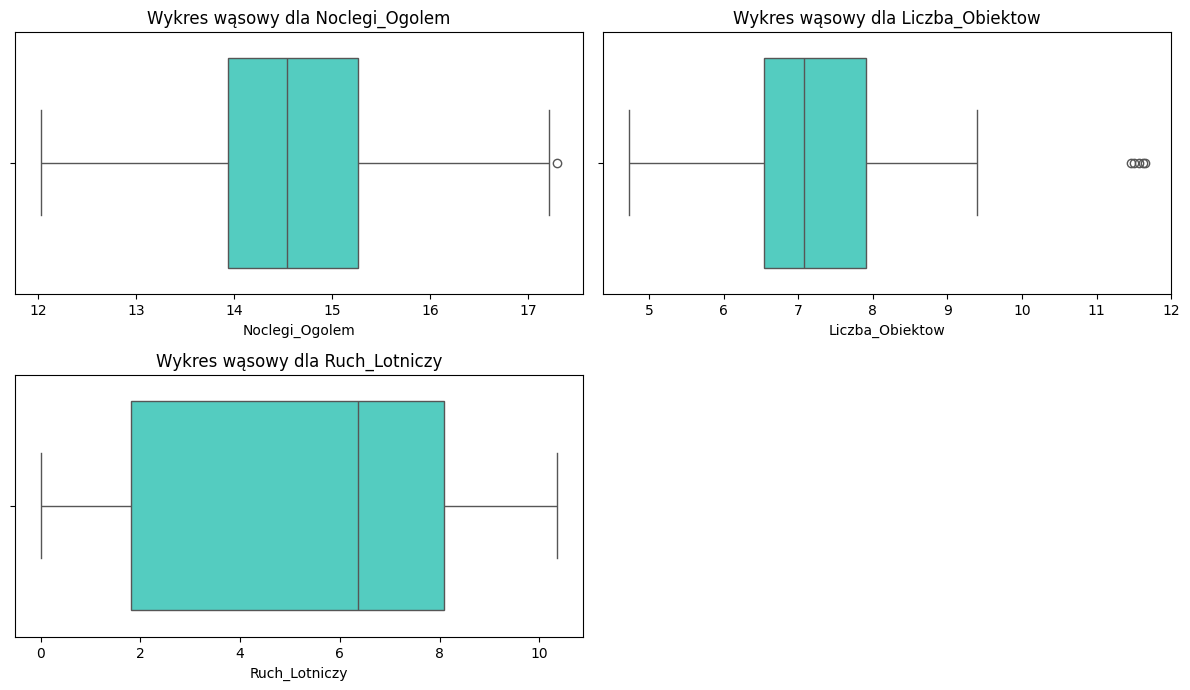

In [16]:


numeric_log = [
    'Noclegi_Ogolem', 
    'Liczba_Obiektow', 
    'Ruch_Lotniczy',    
]

df[numeric_log] = np.log1p(df[numeric_log])



plt.figure(figsize=(12, 10))
for i, col in enumerate(numeric_log, 1):
    plt.subplot(3,2,i)
    sns.boxplot(x=col, data=df, vert=False, color='turquoise')
    plt.title(f'Wykres wąsowy dla {col}')
    plt.tight_layout()
plt.show()   

Przyjrzyjmy sie aktualnemu rozkładowi danych

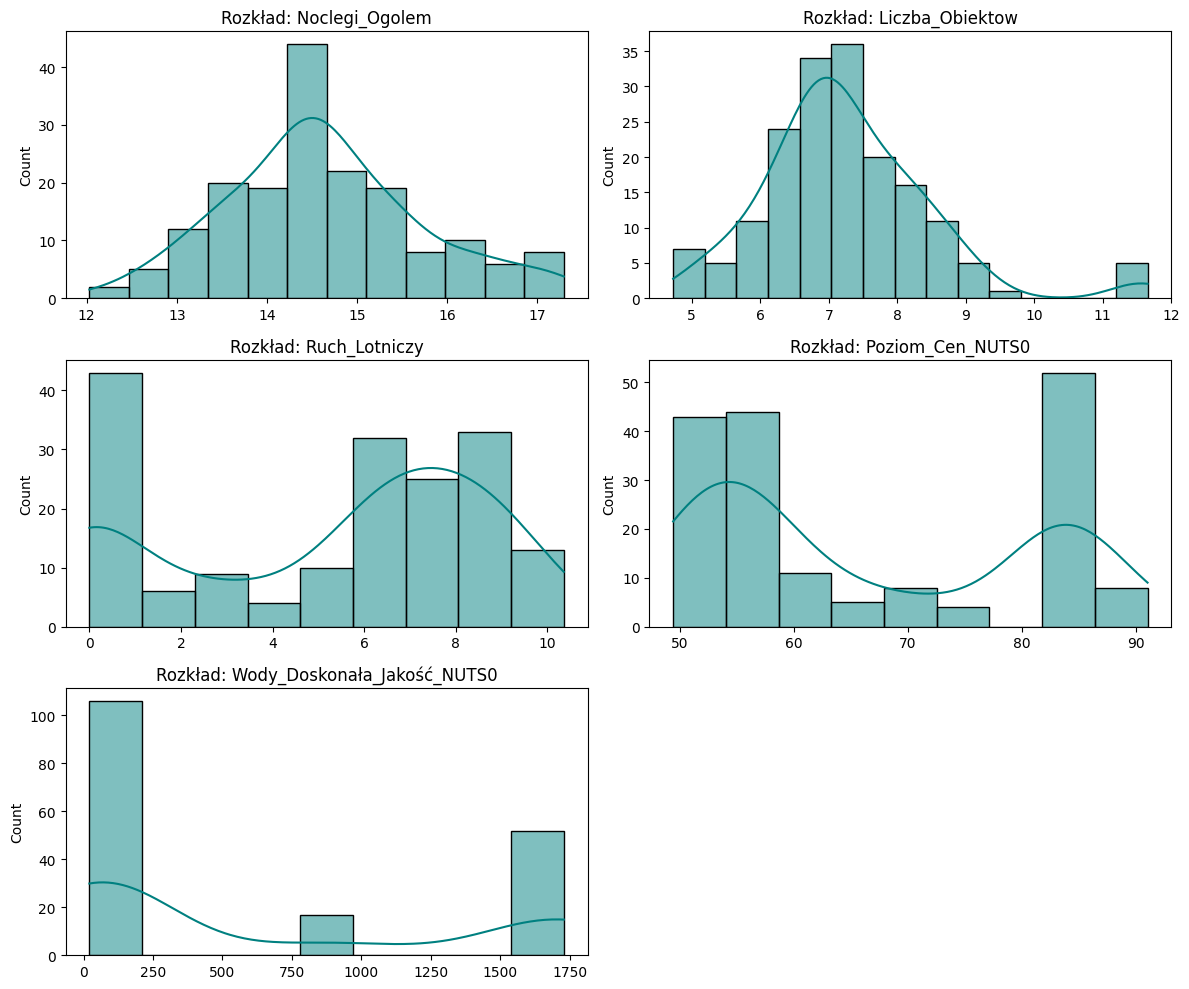

In [17]:
numeric_cols = [
    'Noclegi_Ogolem', 
    'Liczba_Obiektow', 
    'Ruch_Lotniczy', 
    'Poziom_Cen_NUTS0', 
    'Wody_Doskonała_Jakość_NUTS0'
]

plt.figure(figsize=(12, 10))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 2, i)
    sns.histplot(df[col].dropna(), kde=True, color='teal')
    plt.title(f'Rozkład: {col}')
    plt.xlabel('')
plt.tight_layout()
plt.show()

